# Day 048 | Cross-Validation & Hyperparameter Tuning
## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning

**Author:** Ripon Chandra Malo  
**Date:** 2026-05-16  

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| K-Fold CV | Split data into k folds, train on k-1, test on 1 | Validate bearing capacity model on different site subsets |
| Stratified K-Fold | Preserve class distribution in each fold | Ensure each fold has a mix of soil types |
| cross_val_score | One-line CV evaluation | Quick reliability check for our model |
| GridSearchCV | Test all hyperparameter combinations | Systematically try every n_estimators + max_depth combo |
| RandomizedSearchCV | Sample random hyperparameter combos | Faster search over a large parameter space |
| Learning curves | Performance vs training size | How much data do we need for reliable predictions? |

---

## Our Geotechnical Problem

We return to **bearing capacity prediction** using Random Forest. But this time, instead of a single train/test split, we use **cross-validation** to get reliable performance estimates and **hyperparameter tuning** to find the best model configuration.

A single train/test split can be misleading — the model might perform well on one lucky split and poorly on another. Cross-validation tests the model on every data point and gives us confidence intervals.

---

## Part 1: Generate Bearing Capacity Data

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS
# ─────────────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold,
    cross_val_score, GridSearchCV, RandomizedSearchCV,
    learning_curve
)
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score, make_scorer
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
print("All imports successful.")

All imports successful.


In [2]:
# ─────────────────────────────────────────────────────
# GENERATE BEARING CAPACITY DATA
# ─────────────────────────────────────────────────────

n_samples = 150

footing_width = np.round(np.random.uniform(0.5, 4.0, n_samples), 2)
footing_depth = np.round(np.random.uniform(0.5, 3.0, n_samples), 2)
N_value = np.random.randint(5, 50, n_samples)
unit_weight = np.round(np.random.uniform(15.0, 21.0, n_samples), 1)
cohesion = np.round(np.random.uniform(0, 80, n_samples), 1)
friction_angle = np.round(np.random.uniform(15, 40, n_samples), 1)

# Soil type for stratification demos
soil_type = np.where(cohesion > 40, 'Clay',
            np.where(friction_angle > 30, 'Sand', 'Silt'))

# Bearing capacity (Terzaghi-inspired)
Nc = 5.14 + 0.3 * (friction_angle - 15)
Nq = 1.0 + 0.15 * (friction_angle - 15) ** 1.3
Ngamma = 0.5 + 0.08 * (friction_angle - 15) ** 1.5

bearing_capacity = (
    cohesion * Nc
    + unit_weight * footing_depth * Nq
    + 0.5 * unit_weight * footing_width * Ngamma
    + N_value * 3.5
)
noise = np.random.normal(0, 0.10 * bearing_capacity)
bearing_capacity = np.round(np.maximum(bearing_capacity + noise, 30), 1)

df = pd.DataFrame({
    'footing_width': footing_width,
    'footing_depth': footing_depth,
    'N_value': N_value,
    'unit_weight': unit_weight,
    'cohesion': cohesion,
    'friction_angle': friction_angle,
    'soil_type': soil_type,
    'bearing_capacity_kPa': bearing_capacity
})

feature_cols = ['footing_width', 'footing_depth', 'N_value', 'unit_weight', 'cohesion', 'friction_angle']
X = df[feature_cols]
y = df['bearing_capacity_kPa']

print(f"Dataset shape: {df.shape}")
print(f"Soil type distribution: {dict(zip(*np.unique(soil_type, return_counts=True)))}")
print(f"Bearing capacity range: {y.min():.1f} - {y.max():.1f} kPa")
df.head()

Dataset shape: (150, 8)
Soil type distribution: {np.str_('Clay'): np.int64(58), np.str_('Sand'): np.int64(37), np.str_('Silt'): np.int64(55)}
Bearing capacity range: 113.3 - 1510.9 kPa


,footing_width,footing_depth,N_value,unit_weight,cohesion,friction_angle,soil_type,bearing_capacity_kPa
0,1.81,2.77,49,20.7,17.0,29.9,Silt,883.7
1,3.83,1.10,36,20.7,10.9,26.8,Silt,349.6
2,3.06,0.86,34,18.4,1.2,25.3,Silt,223.7
3,2.60,1.72,39,18.8,28.0,23.7,Silt,463.4
4,1.05,2.96,44,17.7,47.2,38.2,Clay,1176.5


---

## Part 2: Why Cross-Validation?

A single train/test split is like testing an engineer on just one project — it doesn't tell you if they're consistently good. Cross-validation tests the model on **every** data point by rotating which fold is the test set.

**K-Fold Cross-Validation:**
1. Split data into k equal folds
2. For each fold: train on k-1 folds, test on the remaining fold
3. Average the k test scores

This gives us a **mean** and **standard deviation** of performance — much more reliable than a single number.

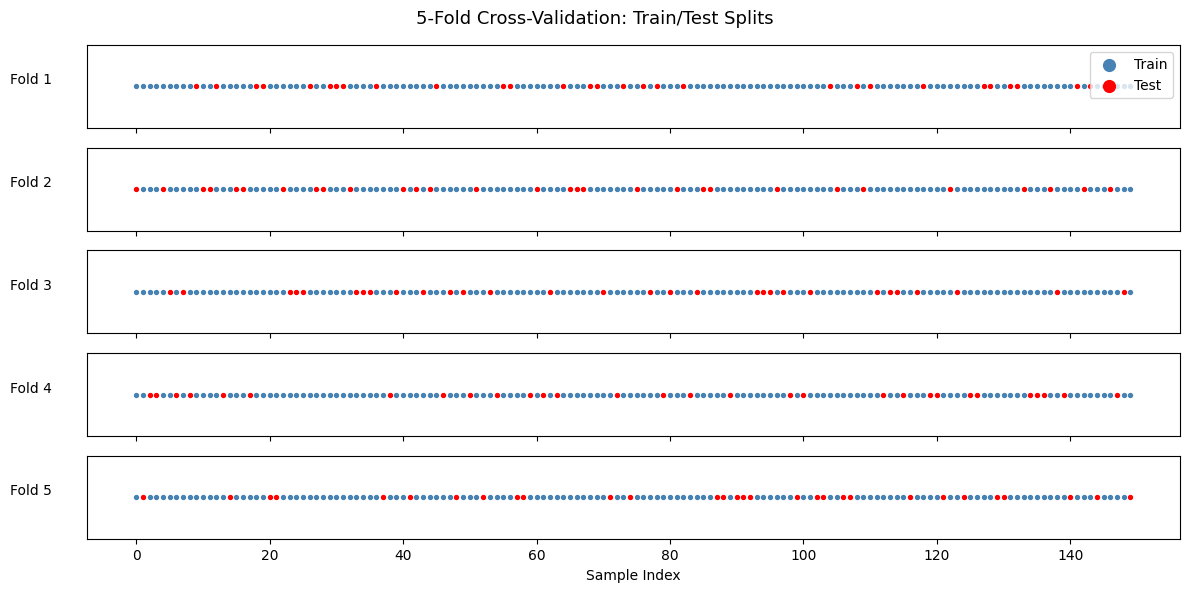

Each sample appears in exactly ONE test fold.
Every sample gets evaluated — no data is wasted.


In [3]:
# ─────────────────────────────────────────────────────
# VISUALIZE K-FOLD SPLITS
# ─────────────────────────────────────────────────────

kf = KFold(n_splits=5, shuffle=True, random_state=42)

fig, axes = plt.subplots(5, 1, figsize=(12, 6), sharex=True)

for i, (train_idx, test_idx) in enumerate(kf.split(X)):
    ax = axes[i]
    ax.scatter(train_idx, [0] * len(train_idx), c='steelblue', s=8, label='Train' if i == 0 else '')
    ax.scatter(test_idx, [0] * len(test_idx), c='red', s=8, label='Test' if i == 0 else '')
    ax.set_ylabel(f'Fold {i+1}', rotation=0, labelpad=40)
    ax.set_yticks([])

axes[0].legend(loc='upper right', markerscale=3)
axes[-1].set_xlabel('Sample Index')
fig.suptitle('5-Fold Cross-Validation: Train/Test Splits', fontsize=13)
plt.tight_layout()
plt.show()

print("Each sample appears in exactly ONE test fold.")
print("Every sample gets evaluated \u2014 no data is wasted.")

In [4]:
# ─────────────────────────────────────────────────────
# SINGLE SPLIT vs CROSS-VALIDATION
# ─────────────────────────────────────────────────────

# Multiple single splits give different results
single_scores = []
for seed in range(20):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
    rf_temp = RandomForestRegressor(n_estimators=100, random_state=42)
    rf_temp.fit(X_tr, y_tr)
    single_scores.append(rf_temp.score(X_te, y_te))

# Cross-validation gives a stable estimate
rf = RandomForestRegressor(n_estimators=100, random_state=42)
cv_scores = cross_val_score(rf, X, y, cv=5, scoring='r2')

print("Single Train/Test Split (20 different splits):")
print(f"  R\u00b2 scores: {[f'{s:.3f}' for s in single_scores[:10]]}...")
print(f"  Mean: {np.mean(single_scores):.4f}, Std: {np.std(single_scores):.4f}")
print(f"  Range: {np.min(single_scores):.4f} to {np.max(single_scores):.4f}")
print()
print("5-Fold Cross-Validation:")
print(f"  R\u00b2 scores: {[f'{s:.4f}' for s in cv_scores]}")
print(f"  Mean: {cv_scores.mean():.4f} \u00b1 {cv_scores.std():.4f}")
print()
print("Cross-validation gives ONE reliable number instead of a range.")

Single Train/Test Split (20 different splits):
  R² scores: ['0.854', '0.813', '0.776', '0.906', '0.880', '0.846', '0.699', '0.841', '0.782', '0.843']...
  Mean: 0.8150, Std: 0.0488
  Range: 0.6987 to 0.9057

5-Fold Cross-Validation:
  R² scores: ['0.8293', '0.7650', '0.8176', '0.8631', '0.8390']
  Mean: 0.8228 ± 0.0326

Cross-validation gives ONE reliable number instead of a range.


---

## Part 3: Stratified K-Fold

In [5]:
# ─────────────────────────────────────────────────────
# STRATIFIED K-FOLD FOR CLASSIFICATION
# ─────────────────────────────────────────────────────

# Demonstrate stratification: ensure each fold has all soil types
le = LabelEncoder()
y_class = le.fit_transform(df['soil_type'])

print("Regular K-Fold \u2014 class distribution per fold:")
print("=" * 55)
kf_regular = KFold(n_splits=5, shuffle=True, random_state=42)
for i, (_, test_idx) in enumerate(kf_regular.split(X)):
    counts = dict(zip(*np.unique(df['soil_type'].iloc[test_idx], return_counts=True)))
    print(f"  Fold {i+1}: {counts}")

print("\nStratified K-Fold \u2014 class distribution per fold:")
print("=" * 55)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for i, (_, test_idx) in enumerate(skf.split(X, y_class)):
    counts = dict(zip(*np.unique(df['soil_type'].iloc[test_idx], return_counts=True)))
    print(f"  Fold {i+1}: {counts}")

print("\nStratified K-Fold ensures each fold represents all soil types.")
print("Use it for classification tasks to avoid biased folds.")

Regular K-Fold — class distribution per fold:
  Fold 1: {'Clay': np.int64(8), 'Sand': np.int64(10), 'Silt': np.int64(12)}
  Fold 2: {'Clay': np.int64(10), 'Sand': np.int64(7), 'Silt': np.int64(13)}
  Fold 3: {'Clay': np.int64(14), 'Sand': np.int64(5), 'Silt': np.int64(11)}
  Fold 4: {'Clay': np.int64(13), 'Sand': np.int64(4), 'Silt': np.int64(13)}
  Fold 5: {'Clay': np.int64(13), 'Sand': np.int64(11), 'Silt': np.int64(6)}

Stratified K-Fold — class distribution per fold:
  Fold 1: {'Clay': np.int64(12), 'Sand': np.int64(7), 'Silt': np.int64(11)}
  Fold 2: {'Clay': np.int64(12), 'Sand': np.int64(7), 'Silt': np.int64(11)}
  Fold 3: {'Clay': np.int64(12), 'Sand': np.int64(7), 'Silt': np.int64(11)}
  Fold 4: {'Clay': np.int64(11), 'Sand': np.int64(8), 'Silt': np.int64(11)}
  Fold 5: {'Clay': np.int64(11), 'Sand': np.int64(8), 'Silt': np.int64(11)}

Stratified K-Fold ensures each fold represents all soil types.
Use it for classification tasks to avoid biased folds.


In [6]:
# ─────────────────────────────────────────────────────
# CROSS_VAL_SCORE WITH DIFFERENT k VALUES
# ─────────────────────────────────────────────────────

rf = RandomForestRegressor(n_estimators=100, random_state=42)

print("Effect of Number of Folds (k):")
print("=" * 55)
print(f"{'k':<5s} {'Mean R\u00b2':>10s} {'Std':>10s} {'Min':>10s} {'Max':>10s}")
print("-" * 55)

for k in [3, 5, 7, 10]:
    scores = cross_val_score(rf, X, y, cv=k, scoring='r2')
    print(f"{k:<5d} {scores.mean():>10.4f} {scores.std():>10.4f} {scores.min():>10.4f} {scores.max():>10.4f}")

print("\n5-fold or 10-fold are the most common choices.")
print("More folds = more compute but slightly less bias in the estimate.")

Effect of Number of Folds (k):
k        Mean R²        Std        Min        Max
-------------------------------------------------------


3         0.8164     0.0411     0.7668     0.8675


5         0.8228     0.0326     0.7650     0.8631


7         0.8211     0.0447     0.7214     0.8763


10        0.8258     0.0655     0.6687     0.9244

5-fold or 10-fold are the most common choices.
More folds = more compute but slightly less bias in the estimate.


---

## Part 4: GridSearchCV

In [7]:
# ─────────────────────────────────────────────────────
# GRID SEARCH OVER HYPERPARAMETERS
# ─────────────────────────────────────────────────────

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10]
}

total_combos = 3 * 4 * 3
print(f"Grid Search: {total_combos} parameter combinations \u00d7 5 folds = {total_combos * 5} model fits")
print()

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    return_train_score=True
)
grid_search.fit(X, y)

print("Grid Search Results:")
print("=" * 55)
print(f"  Best parameters: {grid_search.best_params_}")
print(f"  Best CV R\u00b2:     {grid_search.best_score_:.4f}")
print()

# Top 5 parameter combos
results = pd.DataFrame(grid_search.cv_results_)
top5 = results.nsmallest(5, 'rank_test_score')[['params', 'mean_test_score', 'std_test_score', 'rank_test_score']]
print("Top 5 parameter combinations:")
for _, row in top5.iterrows():
    print(f"  Rank {row['rank_test_score']:.0f}: R\u00b2={row['mean_test_score']:.4f} \u00b1 {row['std_test_score']:.4f}  {row['params']}")

Grid Search: 36 parameter combinations × 5 folds = 180 model fits



Grid Search Results:
  Best parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
  Best CV R²:     0.8286

Top 5 parameter combinations:
  Rank 1: R²=0.8286 ± 0.0298  {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
  Rank 2: R²=0.8285 ± 0.0298  {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 200}
  Rank 3: R²=0.8274 ± 0.0287  {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
  Rank 4: R²=0.8230 ± 0.0352  {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 50}
  Rank 4: R²=0.8230 ± 0.0352  {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}


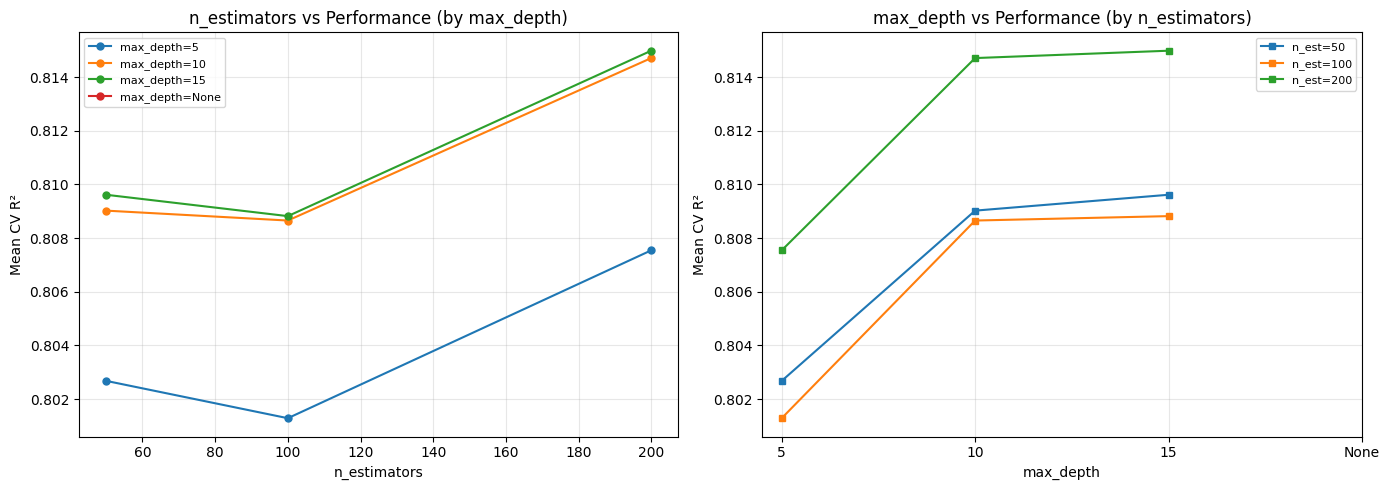

In [8]:
# ─────────────────────────────────────────────────────
# VISUALIZE GRID SEARCH RESULTS
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# n_estimators effect (averaged over other params)
for depth in [5, 10, 15, None]:
    mask = results['param_max_depth'] == depth
    subset = results[mask].groupby('param_n_estimators')[['mean_test_score']].mean()
    label = f'max_depth={depth}' if depth else 'max_depth=None'
    axes[0].plot(subset.index, subset['mean_test_score'], '-o', markersize=5, label=label)

axes[0].set_xlabel('n_estimators')
axes[0].set_ylabel('Mean CV R\u00b2')
axes[0].set_title('n_estimators vs Performance (by max_depth)')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

# max_depth effect
for n_est in [50, 100, 200]:
    mask = results['param_n_estimators'] == n_est
    subset = results[mask].groupby('param_max_depth')[['mean_test_score']].mean()
    axes[1].plot(range(len(subset)), subset['mean_test_score'], '-s', markersize=5, label=f'n_est={n_est}')

axes[1].set_xticks(range(4))
axes[1].set_xticklabels(['5', '10', '15', 'None'])
axes[1].set_xlabel('max_depth')
axes[1].set_ylabel('Mean CV R\u00b2')
axes[1].set_title('max_depth vs Performance (by n_estimators)')
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---

## Part 5: RandomizedSearchCV

In [9]:
# ─────────────────────────────────────────────────────
# RANDOMIZED SEARCH \u2014 LARGER PARAMETER SPACE
# ─────────────────────────────────────────────────────

from scipy.stats import randint, uniform

param_distributions = {
    'n_estimators': randint(50, 500),
    'max_depth': [3, 5, 7, 10, 15, 20, None],
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 10),
    'max_features': uniform(0.3, 0.7)  # fraction of features
}

random_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42),
    param_distributions=param_distributions,
    n_iter=50,  # only 50 random combos (vs thousands for grid)
    cv=5,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)
random_search.fit(X, y)

print("Randomized Search Results (50 iterations):")
print("=" * 55)
print(f"  Best parameters:")
for k, v in random_search.best_params_.items():
    print(f"    {k}: {v}")
print(f"  Best CV R\u00b2: {random_search.best_score_:.4f}")
print()
print(f"Comparison:")
print(f"  GridSearchCV best R\u00b2:       {grid_search.best_score_:.4f} ({total_combos} combos)")
print(f"  RandomizedSearchCV best R\u00b2: {random_search.best_score_:.4f} (50 combos)")
print(f"\nRandomizedSearchCV explores a much larger space with fewer evaluations.")

Randomized Search Results (50 iterations):
  Best parameters:
    max_depth: 10
    max_features: 0.7462902299486491
    min_samples_leaf: 3
    min_samples_split: 2
    n_estimators: 276
  Best CV R²: 0.8218

Comparison:
  GridSearchCV best R²:       0.8286 (36 combos)
  RandomizedSearchCV best R²: 0.8218 (50 combos)

RandomizedSearchCV explores a much larger space with fewer evaluations.


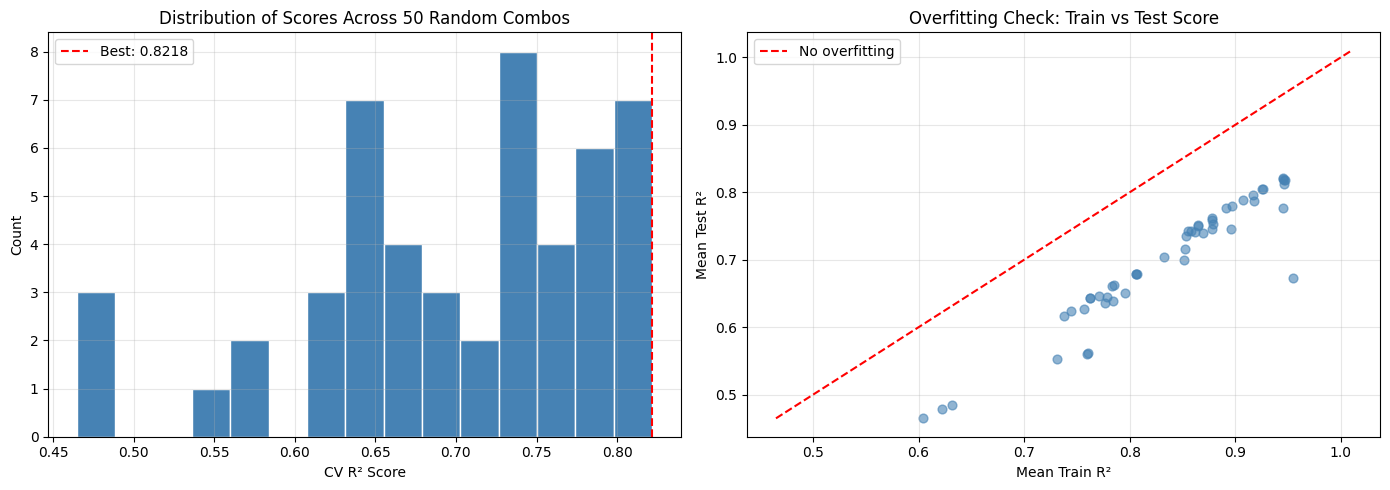

Points far below the red line indicate overfitting.
The best models have both high train AND test scores.


In [10]:
# ─────────────────────────────────────────────────────
# VISUALIZE RANDOM SEARCH EXPLORATION
# ─────────────────────────────────────────────────────

rs_results = pd.DataFrame(random_search.cv_results_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Score distribution
axes[0].hist(rs_results['mean_test_score'], bins=15, color='steelblue', edgecolor='white')
axes[0].axvline(x=random_search.best_score_, color='r', linestyle='--',
               label=f'Best: {random_search.best_score_:.4f}')
axes[0].set_xlabel('CV R\u00b2 Score')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Scores Across 50 Random Combos')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Train vs Test score (overfitting check)
axes[1].scatter(rs_results['mean_train_score'], rs_results['mean_test_score'],
               alpha=0.6, s=40, color='steelblue')
lims = [min(rs_results['mean_test_score'].min(), 0.7), 1.01]
axes[1].plot(lims, lims, 'r--', label='No overfitting')
axes[1].set_xlabel('Mean Train R\u00b2')
axes[1].set_ylabel('Mean Test R\u00b2')
axes[1].set_title('Overfitting Check: Train vs Test Score')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Points far below the red line indicate overfitting.")
print("The best models have both high train AND test scores.")

---

## Part 6: Learning Curves

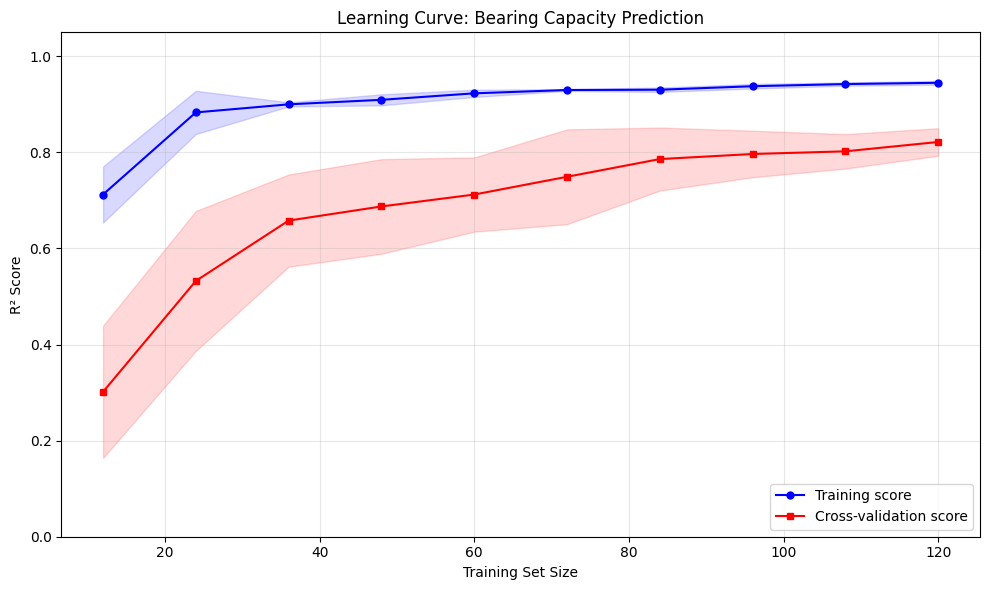

Learning Curve Interpretation:
  With 15 samples: CV R² = 0.3016
  With 120 samples: CV R² = 0.8218

The curve is still rising — collecting more data would help.


In [11]:
# ─────────────────────────────────────────────────────
# LEARNING CURVES \u2014 HOW MUCH DATA DO WE NEED?
# ─────────────────────────────────────────────────────

best_rf = random_search.best_estimator_

train_sizes, train_scores, test_scores = learning_curve(
    best_rf, X, y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='r2',
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
test_mean = test_scores.mean(axis=1)
test_std = test_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(10, 6))

ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                alpha=0.15, color='blue')
ax.fill_between(train_sizes, test_mean - test_std, test_mean + test_std,
                alpha=0.15, color='red')
ax.plot(train_sizes, train_mean, 'b-o', markersize=5, label='Training score')
ax.plot(train_sizes, test_mean, 'r-s', markersize=5, label='Cross-validation score')

ax.set_xlabel('Training Set Size')
ax.set_ylabel('R\u00b2 Score')
ax.set_title('Learning Curve: Bearing Capacity Prediction')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

print("Learning Curve Interpretation:")
print(f"  With 15 samples: CV R\u00b2 = {test_mean[0]:.4f}")
print(f"  With {train_sizes[-1]} samples: CV R\u00b2 = {test_mean[-1]:.4f}")
print()
if test_mean[-1] - test_mean[-3] < 0.02:
    print("The curve is flattening \u2014 more data may not help much.")
    print("Focus on better features or model architecture instead.")
else:
    print("The curve is still rising \u2014 collecting more data would help.")

---

## Part 7: Final Model Evaluation

In [12]:
# ─────────────────────────────────────────────────────
# COMPARE DEFAULT vs TUNED MODEL
# ─────────────────────────────────────────────────────

# Default Random Forest
rf_default = RandomForestRegressor(n_estimators=100, random_state=42)
cv_default = cross_val_score(rf_default, X, y, cv=5, scoring='r2')

# Tuned Random Forest
cv_tuned = cross_val_score(best_rf, X, y, cv=5, scoring='r2')

print("Default vs Tuned Random Forest")
print("=" * 55)
print(f"{'Metric':<25s} {'Default':>13s} {'Tuned':>13s}")
print("-" * 55)
print(f"{'Mean CV R\u00b2':<25s} {cv_default.mean():>13.4f} {cv_tuned.mean():>13.4f}")
print(f"{'Std CV R\u00b2':<25s} {cv_default.std():>13.4f} {cv_tuned.std():>13.4f}")
print(f"{'Min CV R\u00b2':<25s} {cv_default.min():>13.4f} {cv_tuned.min():>13.4f}")
print(f"{'Max CV R\u00b2':<25s} {cv_default.max():>13.4f} {cv_tuned.max():>13.4f}")
print()
improvement = (cv_tuned.mean() - cv_default.mean()) / cv_default.mean() * 100
print(f"Tuning improved R\u00b2 by {improvement:.1f}%")
print(f"\nBest parameters: {random_search.best_params_}")

Default vs Tuned Random Forest
Metric                          Default         Tuned
-------------------------------------------------------
Mean CV R²                       0.8228        0.8218
Std CV R²                        0.0326        0.0287
Min CV R²                        0.7650        0.7669
Max CV R²                        0.8631        0.8504

Tuning improved R² by -0.1%

Best parameters: {'max_depth': 10, 'max_features': np.float64(0.7462902299486491), 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 276}


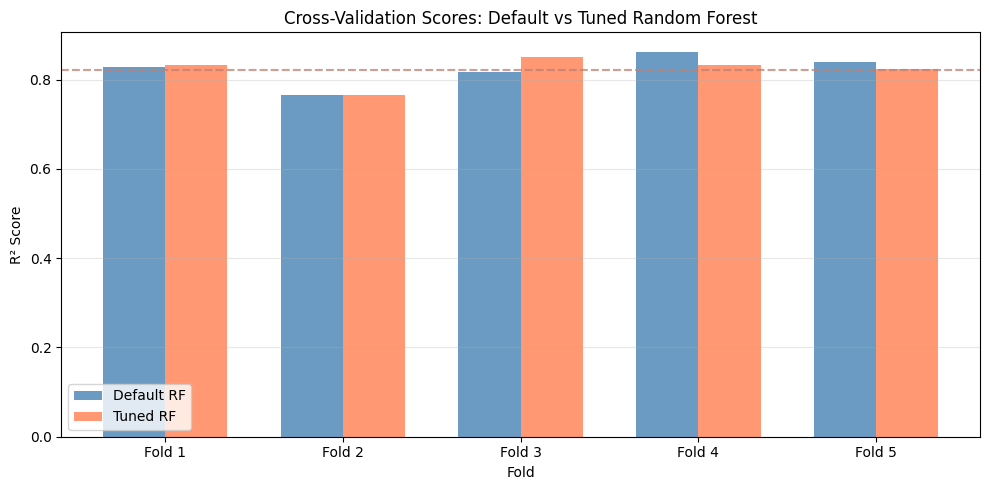

Cross-validation shows consistent improvement across all folds.
This confirms the tuning improvement is real, not due to a lucky split.


In [13]:
# ─────────────────────────────────────────────────────
# FOLD-BY-FOLD COMPARISON
# ─────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 5))

x_pos = np.arange(5)
width = 0.35

ax.bar(x_pos - width/2, cv_default, width, label='Default RF', color='steelblue', alpha=0.8)
ax.bar(x_pos + width/2, cv_tuned, width, label='Tuned RF', color='coral', alpha=0.8)

ax.axhline(y=cv_default.mean(), color='steelblue', linestyle='--', alpha=0.5)
ax.axhline(y=cv_tuned.mean(), color='coral', linestyle='--', alpha=0.5)

ax.set_xlabel('Fold')
ax.set_ylabel('R\u00b2 Score')
ax.set_title('Cross-Validation Scores: Default vs Tuned Random Forest')
ax.set_xticks(x_pos)
ax.set_xticklabels([f'Fold {i+1}' for i in range(5)])
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("Cross-validation shows consistent improvement across all folds.")
print("This confirms the tuning improvement is real, not due to a lucky split.")

---

## Practice Exercises

### Exercise 1: Leave-One-Out CV
Use `cv=n_samples` (Leave-One-Out) and compare with 5-fold CV. Is the score different? How much longer does it take?

### Exercise 2: RMSE Scoring
Repeat GridSearchCV using `scoring='neg_mean_squared_error'` instead of `scoring='r2'`. Do you get the same best parameters?

### Exercise 3: Nested CV
Use nested cross-validation (outer CV for evaluation, inner CV for tuning) to get an unbiased estimate of the tuned model's performance.

In [14]:
# EXERCISE 1: Leave-One-Out CV
# from sklearn.model_selection import LeaveOneOut
# import time
# rf_loo = RandomForestRegressor(n_estimators=50, random_state=42)
# start = time.time()
# loo_scores = cross_val_score(rf_loo, X, y, cv=LeaveOneOut(), scoring='r2')
# elapsed = time.time() - start
# print(f"LOO CV R2: {loo_scores.mean():.4f}, Time: {elapsed:.1f}s")

In [15]:
# EXERCISE 2: RMSE scoring
# grid_rmse = GridSearchCV(
#     RandomForestRegressor(random_state=42),
#     param_grid={'n_estimators': [50, 100, 200], 'max_depth': [5, 10, None]},
#     cv=5, scoring='neg_mean_squared_error', n_jobs=-1
# )
# grid_rmse.fit(X, y)
# print(f"Best params (RMSE): {grid_rmse.best_params_}")
# print(f"Best RMSE: {np.sqrt(-grid_rmse.best_score_):.2f} kPa")

---

## Key Takeaways

1. **Cross-validation gives reliable performance estimates**. A single train/test split can be misleading. K-Fold CV tests on every data point and provides mean + standard deviation.

2. **Stratified K-Fold preserves class balance** in each fold. Use it for classification tasks where some classes are underrepresented (e.g., rare soil types).

3. **GridSearchCV tries every combination** systematically. It guarantees finding the best parameters within the grid, but can be slow with large parameter spaces.

4. **RandomizedSearchCV is more efficient** for large spaces. It samples random combinations and often finds equally good parameters with far fewer evaluations.

5. **Learning curves reveal data needs**. If the curve is still rising, collect more data. If it has flattened, focus on better features or models instead.

---

## How This Connects to ML

| What We Did Today | ML Equivalent |
|-------------------|---------------|
| Multiple train/test splits | Variance of single-split evaluation |
| 5-Fold cross-validation | Robust model evaluation |
| Stratified K-Fold | Balanced sampling for classification |
| GridSearchCV | Exhaustive hyperparameter optimization |
| RandomizedSearchCV | Efficient hyperparameter search |
| Learning curves | Data efficiency analysis |
| Default vs tuned comparison | Model selection with statistical confidence |

---

*Day 048 of 100 — One test is a guess; cross-validation is a verdict!*